# MNIST Handwritten Digit Recognition

## Project Overview
This project uses Machine Learning algorithms to recognize handwritten digits (0–9) from images.

## Algorithms
- K-Nearest Neighbors (KNN)
- Support Vector Machine (SVM)
- Random Forest Classifier

## Objective
To train, evaluate, and compare different machine learning models for handwritten digit recognition.

import numpy as np
import pandas as pd
import sklearn

print("Libraries imported successfully!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

In [1]:
import numpy as np
import pandas as pd
import sklearn

print("Libraries imported successfully!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

Libraries imported successfully!
NumPy: 2.5.4
Pandas: 3.1.0
Scikit-learn: 1.9.1


In [2]:
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns
import streamlit as st

print("All libraries imported successfully!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)

All libraries imported successfully!
NumPy: 2.5.4
Pandas: 3.1.0
Scikit-learn: 1.9.1


In [3]:
from sklearn.datasets import fetch_openml

print("Downloading MNIST...")

mnist = fetch_openml(
    "mnist_784",
    version=1,
    as_frame=False,
    parser="liac-arff"
)

X = mnist.data
y = mnist.target.astype(int)

print("Dataset loaded successfully!")
print("X shape:", X.shape)
print("y shape:", y.shape)


Dataset loaded successfully!
X shape: (70000, 784)
y shape: (70000,)


In [4]:
print("Dataset shape:", X.shape)
print("Number of images:", len(X))
print("Number of unique digits:", len(set(y)))
print("First 10 labels:", y[:10])
print("Pixel values range:", X.min(), "to", X.max())

Dataset shape: (70000, 784)
Number of images: 70000
Number of unique digits: 10
First 10 labels: [5 0 4 1 9 2 1 3 1 4]
Pixel values range: 0.0 to 255.0


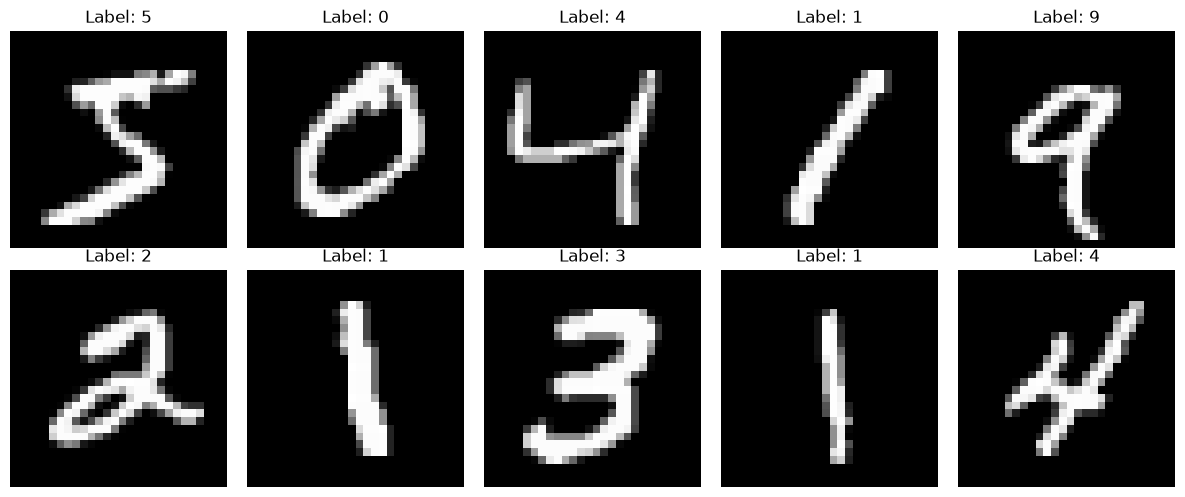

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(X[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"Label: {y[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
X_train = X[:60000]
X_test = X[60000:]

y_train = y[:60000]
y_test = y[60000:]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (60000, 784)
Testing data: (10000, 784)


In [7]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Scaling completed!")

Scaling completed!


In [8]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import time

print("Algorithms imported successfully!")

Algorithms imported successfully!


In [9]:
X_train_small = X_train[:10000]
y_train_small = y_train[:10000]

print("Training samples:", X_train_small.shape)
print("Testing samples:", X_test.shape)

Training samples: (10000, 784)
Testing samples: (10000, 784)


In [10]:
start = time.time()

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_small, y_train_small)

knn_predictions = knn.predict(X_test)

knn_accuracy = accuracy_score(y_test, knn_predictions)

print("KNN Accuracy:", knn_accuracy)
print("Time taken:", round(time.time() - start, 2), "seconds")

KNN Accuracy: 0.9463
Time taken: 1.78 seconds


In [11]:
start = time.time()

svm = SVC(kernel="linear")
svm.fit(X_train_small, y_train_small)

svm_predictions = svm.predict(X_test)

svm_accuracy = accuracy_score(y_test, svm_predictions)

print("SVM Accuracy:", svm_accuracy)
print("Time taken:", round(time.time() - start, 2), "seconds")

SVM Accuracy: 0.917
Time taken: 17.23 seconds


In [12]:
start = time.time()

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_small, y_train_small)

rf_predictions = rf.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Random Forest Accuracy:", rf_accuracy)
print("Time taken:", round(time.time() - start, 2), "seconds")

Random Forest Accuracy: 0.9503
Time taken: 6.95 seconds


In [13]:
import pandas as pd

results = pd.DataFrame({
    "Model": ["KNN", "SVM", "Random Forest"],
    "Accuracy": [knn_accuracy, svm_accuracy, rf_accuracy]
})

print(results)

           Model  Accuracy
0            KNN    0.9463
1            SVM    0.9170
2  Random Forest    0.9503


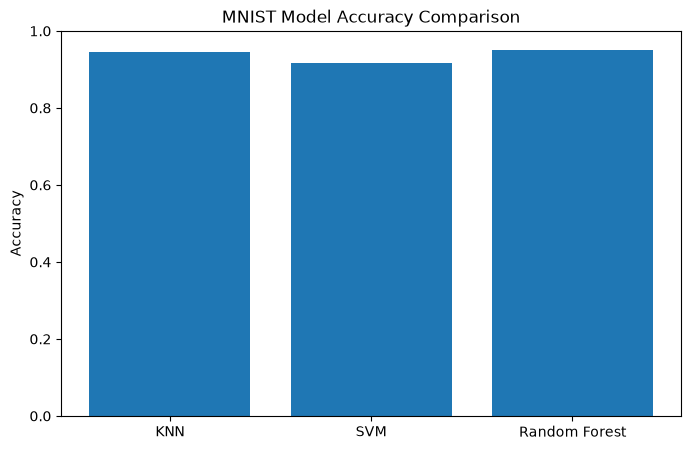

In [14]:
plt.figure(figsize=(8, 5))
plt.bar(results["Model"], results["Accuracy"])
plt.title("MNIST Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

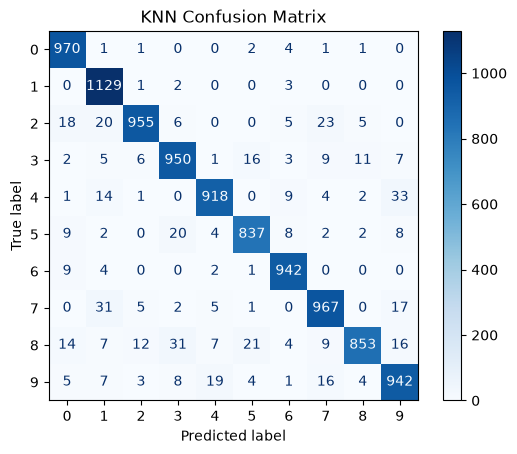

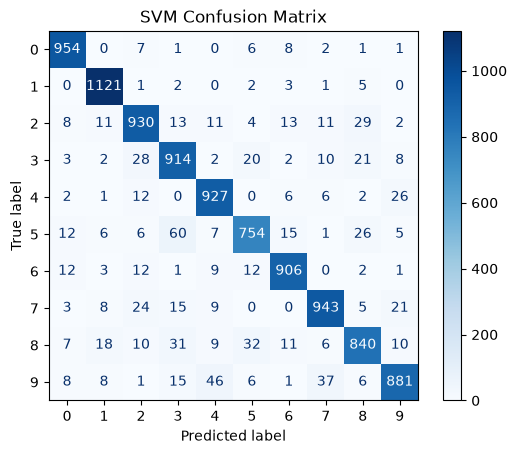

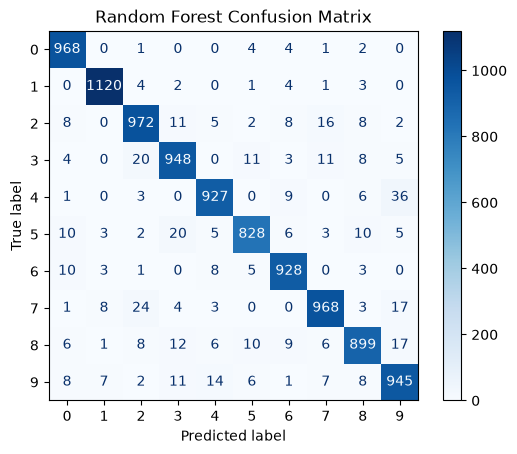

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

models = {
    "KNN": knn,
    "SVM": svm,
    "Random Forest": rf
}

for name, model in models.items():
    y_pred = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, cmap="Blues"
    )
    plt.title(name + " Confusion Matrix")
    plt.show()

In [16]:
from sklearn.metrics import classification_report, accuracy_score

for name, model in models.items():
    y_pred = model.predict(X_test)

    print("\n", "=" * 40)
    print(name)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))


KNN
Accuracy: 0.9463
              precision    recall  f1-score   support

           0       0.94      0.99      0.97       980
           1       0.93      0.99      0.96      1135
           2       0.97      0.93      0.95      1032
           3       0.93      0.94      0.94      1010
           4       0.96      0.93      0.95       982
           5       0.95      0.94      0.94       892
           6       0.96      0.98      0.97       958
           7       0.94      0.94      0.94      1028
           8       0.97      0.88      0.92       974
           9       0.92      0.93      0.93      1009

    accuracy                           0.95     10000
   macro avg       0.95      0.95      0.95     10000
weighted avg       0.95      0.95      0.95     10000


SVM
Accuracy: 0.917
              precision    recall  f1-score   support

           0       0.95      0.97      0.96       980
           1       0.95      0.99      0.97      1135
           2       0.90      0.90  

In [17]:
import joblib
from sklearn.metrics import accuracy_score

best_model_name = max(
    models,
    key=lambda name: accuracy_score(
        y_test, models[name].predict(X_test)
    )
)

best_model = models[best_model_name]

joblib.dump(best_model, "best_mnist_model.pkl")

print("Best model:", best_model_name)
print("Model saved successfully!")

Best model: Random Forest
Model saved successfully!


In [18]:

# Identify commonly confused digits using Random Forest

from sklearn.metrics import confusion_matrix
import numpy as np
import pandas as pd

cm = confusion_matrix(y_test, rf_predictions)

# Ignore the diagonal because those are correct predictions
confusion_without_diagonal = cm.copy()
np.fill_diagonal(confusion_without_diagonal, 0)

# Find the most frequent misclassifications
confusions = []

for actual in range(10):
    for predicted in range(10):
        if confusion_without_diagonal[actual, predicted] > 0:
            confusions.append({
                "Actual Digit": actual,
                "Predicted Digit": predicted,
                "Number of Errors": confusion_without_diagonal[actual, predicted]
            })

confusion_df = pd.DataFrame(confusions)

confusion_df = confusion_df.sort_values(
    by="Number of Errors",
    ascending=False
)

print("Top 10 Most Common Misclassifications:")
display(confusion_df.head(10))


Top 10 Most Common Misclassifications:


,Actual Digit,Predicted Digit,Number of Errors
30,4,9,36
48,7,2,24
34,5,3,20
20,3,2,20
52,7,9,17
61,8,9,17
16,2,7,16
66,9,4,14
56,8,3,12
65,9,3,11


### Analysis of Common Misclassifications

The Random Forest classifier makes some mistakes when handwritten digits have similar shapes.

The most frequent confusion was between digits **4 and 9**, with 36 incorrect predictions. Other common confusions included 7 as 2 (24 errors), 5 as 3 (20 errors), and 3 as 2 (20 errors).

These errors may occur because handwritten digits can have different shapes and writing styles. Overall, the model achieves good accuracy, but it may struggle with certain visually similar handwritten digits.

In [19]:
from pathlib import Path
from PIL import Image
import numpy as np

# Create a folder for sample images
sample_folder = Path("sample_images")
sample_folder.mkdir(exist_ok=True)

# Save 3 examples of each digit from the official test dataset
y_test_numeric = np.asarray(y_test).astype(int)

for digit in range(10):
    indices = np.where(y_test_numeric == digit)[0][:3]

    for number, index in enumerate(indices, start=1):
        image_array = (X_test[index].reshape(28, 28) * 255).astype("uint8")

        image = Image.fromarray(image_array)
        image.save(sample_folder / f"digit_{digit}_{number}.png")

print("30 MNIST sample images saved successfully!")

30 MNIST sample images saved successfully!


In [20]:
import joblib
import gzip
import shutil

with open("best_mnist_model.pkl", "rb") as f_in:
    with gzip.open("best_mnist_model_compressed.pkl.gz", "wb") as f_out:
        shutil.copyfileobj(f_in, f_out)

print("Model compressed successfully!")

Model compressed successfully!
